# 07 - Channel Performance & Geographic Analysis 📈🌍

**Channel questions:**
- Which distribution channel brings the most bookings, revenue, and cancellations?
- Is there a channel with high volume but a costly cancellation rate (e.g. OTA)?

**Geographic questions:**
- Which countries send the most guests, and how does that compare to revenue and cancellation rate?

In [1]:
import sys
sys.path.append('..')

import pandas as pd

from src.config import CLEAN_DATA_PATH
from src.feature_engineering import add_stay_features, add_revenue
from src.analysis import channel_performance_table, top_countries_by_volume, revenue_by_country, cancellation_rate_by_top_countries
from src.visualization import plot_top_countries

df = pd.read_csv(CLEAN_DATA_PATH)
df = add_stay_features(df)
df = add_revenue(df)

## Channel performance table

Bookings, revenue, and cancellation rate per `distribution_channel`.

In [2]:
channel_table = channel_performance_table(df)
channel_table

,bookings,revenue,cancellation_rate
distribution_channel,,,
TA/TO,68974,28486499.71,0.309914
Direct,12918,4942864.13,0.148475
Corporate,5061,833616.82,0.127643
GDS,181,43628.82,0.198895
Undefined,5,1171.00,0.800000


## Top countries by bookings / revenue / cancellation rate

country
PRT    27761
GBR    10419
FRA     8819
ESP     7220
DEU     5385
ITA     3060
IRL     3014
BEL     2077
BRA     1993
NLD     1909
Name: count, dtype: int64

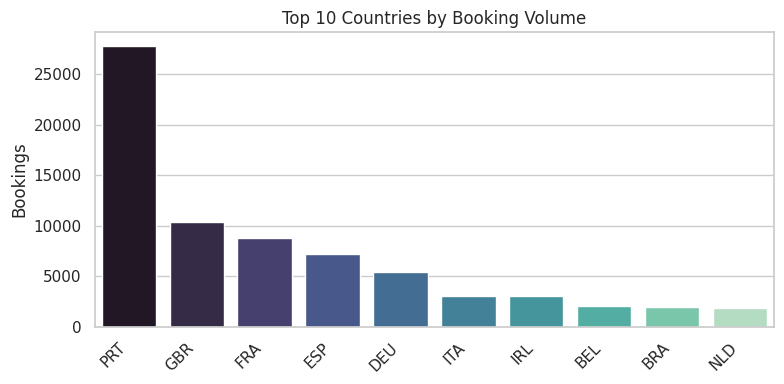

In [3]:
top_by_volume = top_countries_by_volume(df, top_n=10)
plot_top_countries(top_by_volume, 'Top 10 Countries by Booking Volume', 'Bookings', '18_top_countries_volume.png')
top_by_volume

In [4]:
top_by_revenue = revenue_by_country(df, top_n=10)
top_by_cancel = cancellation_rate_by_top_countries(df, top_n=10)
geo_summary = pd.DataFrame({
    'bookings': top_by_volume,
    'revenue': top_by_revenue.reindex(top_by_volume.index),
    'cancellation_rate': top_by_cancel.reindex(top_by_volume.index),
})
geo_summary

,bookings,revenue,cancellation_rate
country,,,
PRT,27761,9105409.42,0.352833
GBR,10419,4713908.01,0.190229
FRA,8819,3594052.87,0.196281
ESP,7220,2936754.83,0.256925
DEU,5385,2113113.24,0.195543
ITA,3060,1211384.46,0.351307
IRL,3014,1536605.05,0.221632
BEL,2077,881121.63,0.197882
BRA,1993,795122.03,0.364777


## Geographic visualization (optional)

A choropleth needs `plotly`, which isn't a core project dependency — the bar chart above already answers the "which countries matter" question, so it's skipped here to keep the dependency list lean.

## Key insight

In [5]:
riskiest_channel = channel_table.loc[channel_table['bookings'] >= 50, 'cancellation_rate'].idxmax()
biggest_channel = channel_table['bookings'].idxmax()
print(f"- '{biggest_channel}' brings the most bookings ({channel_table.loc[biggest_channel, 'bookings']:,}) and the most revenue.")
print(f"- Among channels with meaningful volume (50+ bookings), '{riskiest_channel}' has the highest cancellation rate ({channel_table.loc[riskiest_channel, 'cancellation_rate']:.1%}) — a volume/risk trade-off worth flagging to revenue management.")
print(f"- Guest volume is concentrated in a handful of countries: {', '.join(top_by_volume.index[:3])} alone account for {top_by_volume.head(3).sum() / len(df):.1%} of all bookings.")

- 'TA/TO' brings the most bookings (68,974) and the most revenue.
- Among channels with meaningful volume (50+ bookings), 'TA/TO' has the highest cancellation rate (31.0%) — a volume/risk trade-off worth flagging to revenue management.
- Guest volume is concentrated in a handful of countries: PRT, GBR, FRA alone account for 53.9% of all bookings.
